# The Sentiment Signal: Weeks 1–3
**Kevin (yy6074), Kelly (lx2455), Yuwei (yz13019)**  
Mid-program handoff, EDA stage. Prepared 20 October 2026.

**Purpose:** demonstrate a reproducible analysis of a synthetic social media dataset,
define a bounded sentiment classification problem, and prepare for instructor feedback.
No models or hypothesis tests are run in this notebook.

The publisher discloses that ChatGPT generated these examples. All platform,
geography and temporal patterns describe the simulated sample.
Source: https://www.kaggle.com/datasets/kashishparmar02/social-media-sentiments-analysis-dataset/data
Provenance: ../initial_analysis/sources/kaggle_metadata.json.

Run all cells in order from this folder. The source CSV remains unchanged.

In [1]:
from pathlib import Path
import hashlib, json, re, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE = Path.cwd()
if not (BASE.parent / 'sentimentdataset.csv').exists():
    candidate = BASE / 'weeks_1_3'
    if (candidate.parent / 'sentimentdataset.csv').exists():
        BASE = candidate
    else:
        raise FileNotFoundError('Run from weeks_1_3 or its Group Project parent folder.')
SOURCE = BASE.parent / 'sentimentdataset.csv'
for folder in ['data', 'tables', 'figures']:
    (BASE / folder).mkdir(exist_ok=True)
raw = pd.read_csv(SOURCE)
input_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
print('Raw shape:', raw.shape, '  SHA-256:', input_hash)
display(raw.head(3))

Raw shape: (732, 15)   SHA-256: 725c6f7bc928c2bf741094f37078024b305982523fe6d0b8cb20a6cf5275c63b


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15


## Week 1: dataset exploration
Unit of analysis: one simulated post record. The file has text and a supplied emotion
label, plus date/time, user, platform, hashtags, engagement counts and location.
The two unnamed columns are export indices. License: CC0-1.0 per publisher metadata.
There is no sampling frame, verified ground truth annotation process, impressions,
follower count, demographic information or timestamp timezone.

In [2]:
inventory = pd.DataFrame({
    'column': raw.columns,
    'dtype': raw.dtypes.astype(str).values,
    'missing_cells': raw.isna().sum().values,
    'unique_raw_values': raw.nunique().values,
})
inventory.to_csv(BASE / 'tables/raw_inventory.csv', index=False)
display(inventory)
print('Publisher origin disclosure:')
metadata = json.loads((BASE.parent / 'initial_analysis/sources/kaggle_metadata.json').read_text())
print(metadata['info']['userSpecifiedSources'])

,column,dtype,missing_cells,unique_raw_values
0,Unnamed: 0.1,int64,0,732
1,Unnamed: 0,int64,0,732
2,Text,object,0,707
3,Sentiment,object,0,279
4,Timestamp,object,0,683
5,User,object,0,685
6,Platform,object,0,4
7,Hashtags,object,0,697
8,Retweets,float64,0,26
9,Likes,float64,0,38


Publisher origin disclosure:
Origin: Generated by ChatGPT, a state-of-the-art language model.
Intent: Created to simulate diverse social media content for sentiment analysis.
Nature: Synthetic data with no direct representation of real-world individuals or events.


## Week 2: cleaning with Pandas and NumPy
Normalize Unicode and whitespace while retaining emoji, punctuation and negation.
Remove repeated records using the 13 substantive source fields. Keep the first
occurrence and record the retained record number for every removal. Repeated text
with different metadata remains in the analysis and receives a grouping identifier.

In [3]:
clean = raw.copy()
normalization = []
for column in clean.select_dtypes('object'):
    original = clean[column].copy()
    clean[column] = clean[column].map(
        lambda v: re.sub(r'\s+', ' ', unicodedata.normalize('NFC', v)).strip()
        if isinstance(v, str) else v
    ).replace('', pd.NA)
    normalization.append({
        'column': column,
        'changed_rows': int((original.fillna('') != clean[column].fillna('')).sum()),
        'unique_before': original.nunique(), 'unique_after': clean[column].nunique(),
    })
clean.insert(0, 'source_record', np.arange(2, len(clean) + 2))
substantive = [c for c in raw if not c.startswith('Unnamed')]
duplicate_mask = clean.duplicated(subset=substantive, keep='first')
duplicate_of = clean.groupby(substantive, dropna=False).source_record.transform('min')
removed = clean.loc[duplicate_mask].copy()
removed['duplicate_of_source_record'] = duplicate_of[duplicate_mask]
removed.to_csv(BASE / 'data/removed_duplicate_records.csv', index=False)
clean = clean.loc[~duplicate_mask].copy()
clean.rename(columns={'Unnamed: 0.1': 'source_index_1', 'Unnamed: 0': 'source_index_2'}, inplace=True)
clean.columns = [c.lower() for c in clean.columns]
clean['timestamp'] = pd.to_datetime(clean.timestamp, format='%Y-%m-%d %H:%M:%S', errors='coerce')
checks = {'raw_rows': len(raw), 'duplicate_rows_removed': int(duplicate_mask.sum()), 'retained_rows': len(clean),
          'missing_after_normalization': int(clean.isna().sum().sum()),
          'invalid_timestamps': int(clean.timestamp.isna().sum())}
for col in ['year', 'month', 'day', 'hour']:
    derived = getattr(clean.timestamp.dt, col)
    checks[col + '_mismatches'] = int((clean[col] != derived).sum())
    clean[col] = derived.astype('Int64')
for col in ['likes', 'retweets']:
    clean[col] = pd.to_numeric(clean[col], errors='coerce')
    checks[col + '_invalid'] = int((clean[col].isna() | clean[col].lt(0) | clean[col].mod(1).ne(0)).sum())
    assert checks[col + '_invalid'] == 0
    clean[col] = clean[col].astype('Int64')
assert len(raw) == len(clean) + len(removed)
assert clean.source_record.is_unique
assert checks['invalid_timestamps'] == checks['missing_after_normalization'] == 0
pd.DataFrame(normalization).to_csv(BASE / 'tables/normalization_log.csv', index=False)
(BASE / 'data/cleaning_checks.json').write_text(json.dumps(checks, indent=2))
display(pd.DataFrame(normalization))
display(pd.Series(checks, name='result').to_frame())

,column,changed_rows,unique_before,unique_after
0,Text,728,707,706
1,Sentiment,732,279,191
2,Timestamp,0,683,683
3,User,732,685,670
4,Platform,732,4,3
5,Hashtags,732,697,692
6,Country,723,115,33


,result
raw_rows,732
duplicate_rows_removed,22
retained_rows,710
missing_after_normalization,0
invalid_timestamps,0
year_mismatches,0
month_mismatches,0
day_mismatches,0
hour_mismatches,0
likes_invalid,0


In [4]:
clean['text_lower'] = clean.text.str.lower()
clean['text_group_id'] = clean.text_lower.map(lambda v: hashlib.sha256(v.encode()).hexdigest()[:16])
clean['repeated_text'] = clean.text_group_id.duplicated(keep=False)
clean['text_char_count'] = clean.text.str.len()
clean['text_word_count'] = clean.text.str.split().str.len()
clean['total_interactions'] = clean.likes + clean.retweets
clean['year_month'] = clean.timestamp.dt.strftime('%Y-%m')
clean['weekday'] = clean.timestamp.dt.day_name()
clean['hashtag_list'] = clean.hashtags.map(lambda v: sorted(set(re.findall(r'#(\w+)', v.lower()))))
clean['hashtag_count'] = clean.hashtag_list.str.len()
clean['is_weekend'] = np.isin(clean.timestamp.dt.weekday.to_numpy(), [5, 6])
clean['log1p_interactions'] = np.log1p(clean.total_interactions.to_numpy(dtype=float))
export = clean.copy()
export.hashtag_list = export.hashtag_list.map(json.dumps)
export.to_csv(BASE / 'data/posts_prepared.csv', index=False, date_format='%Y-%m-%d %H:%M:%S')
# Compare against the earlier independent pipeline.
earlier = pd.read_csv(BASE.parent / 'initial_analysis/sentiment_cleaned.csv')
assert set(clean.source_record) == set(earlier.source_record)
assert clean.likes.sum() == earlier.likes.sum()
assert clean.retweets.sum() == earlier.retweets.sum()
assert not clean.text.isna().any()
assert clean.hashtag_count.eq(2).all()
print('Retained:', len(clean), ' Identical text groups:', clean.loc[clean.repeated_text, 'text_group_id'].nunique())
display(clean[['text_word_count', 'likes', 'retweets', 'total_interactions', 'hashtag_count']].describe())
print('NumPy interaction quartiles:', np.quantile(clean.total_interactions.to_numpy(dtype=float), [.25, .5, .75]))

Retained: 710  Identical text groups: 4


,text_word_count,likes,retweets,total_interactions,hashtag_count
count,710.000000,710.0,710.0,710.0,710.0
mean,13.085915,42.98169,21.549296,64.530986,2.0
std,4.850917,14.202682,7.117567,21.312995,0.0
min,4.000000,10.0,5.0,15.0,2.0
25%,9.000000,35.0,18.0,53.0,2.0
50%,13.000000,43.0,22.0,65.0,2.0
75%,17.000000,50.0,25.0,75.0,2.0
max,25.000000,80.0,40.0,120.0,2.0


NumPy interaction quartiles: [53. 65. 75.]


## Week 3: EDA, visualizations and feature selection
Counts and percentages below use deduplicated posts. A frequent label is not a
validated polarity category. A hashtag can occur alongside another hashtag, so
shares across hashtags do not sum to 100%. All findings are descriptive.

,sentiment,posts,share_pct,support_band
0,Positive,45,6.338028,10+
1,Joy,44,6.197183,10+
2,Excitement,37,5.211268,10+
3,Neutral,18,2.535211,10+
4,Contentment,18,2.535211,10+
5,Gratitude,17,2.394366,10+
6,Curiosity,16,2.253521,10+
7,Serenity,15,2.112676,10+
8,Happy,14,1.971831,10+
9,Despair,11,1.549296,10+


,support_band,labels,posts
0,1,81,81
1,2–4,69,190
2,5–9,30,193
3,10+,11,246


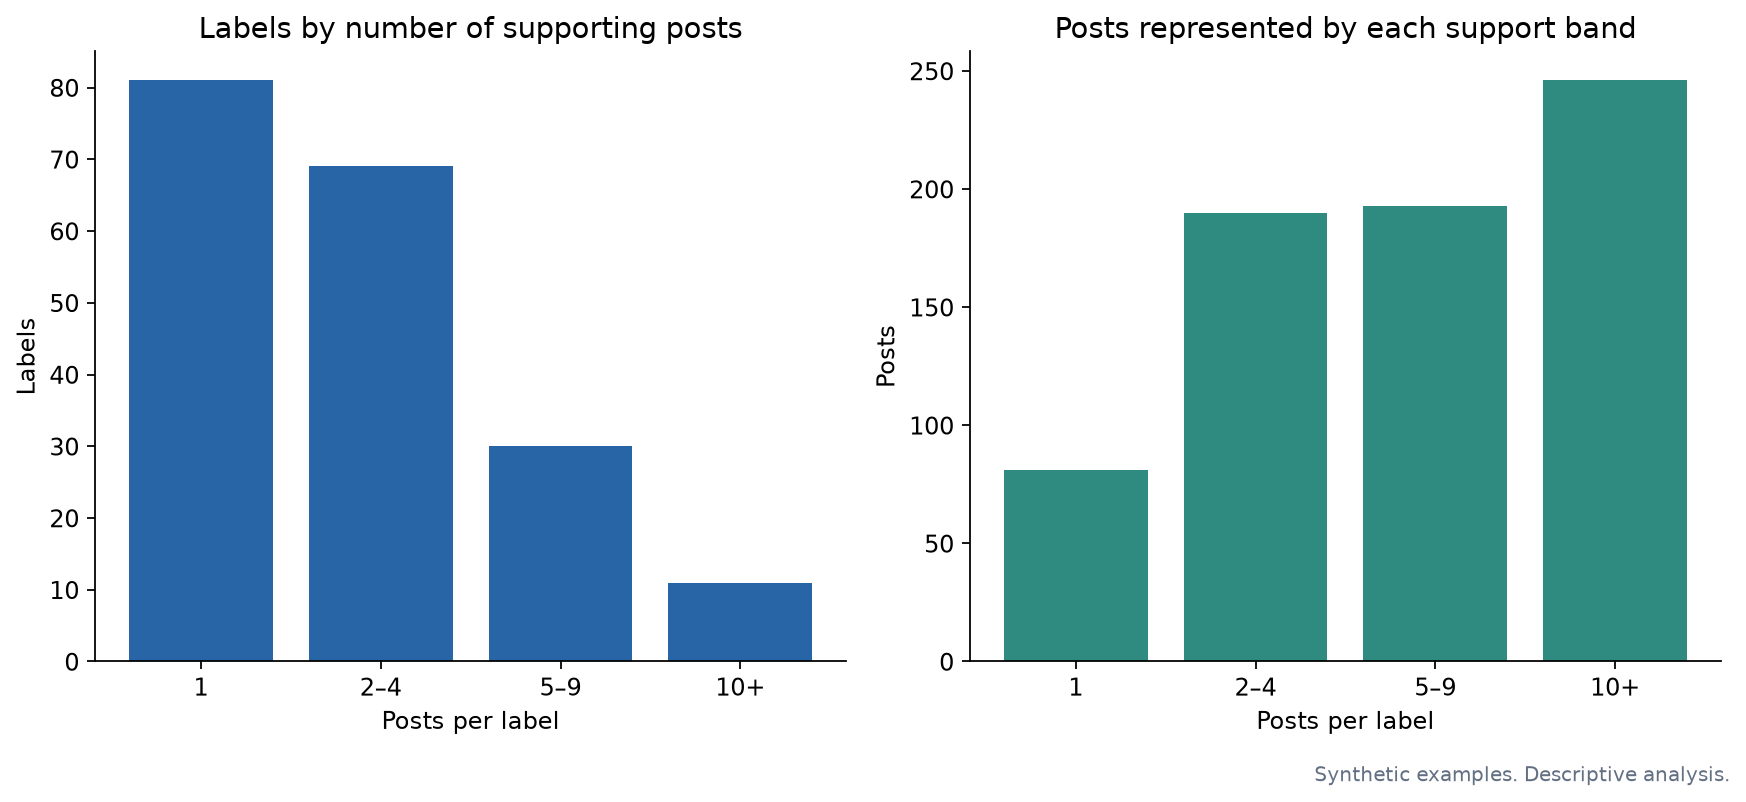

In [5]:
support = clean.sentiment.value_counts().rename_axis('sentiment').reset_index(name='posts')
support['share_pct'] = support.posts / len(clean) * 100
support['support_band'] = pd.cut(support.posts, bins=[0, 1, 4, 9, 1000], labels=['1', '2–4', '5–9', '10+'])
support.to_csv(BASE / 'tables/label_support.csv', index=False)
band = support.groupby('support_band', observed=False).agg(labels=('sentiment', 'size'), posts=('posts', 'sum')).reset_index()
band.to_csv(BASE / 'tables/label_support_bands.csv', index=False)
display(support.head(15))
display(band)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
def save_chart(fig, name):
    fig.text(.99, .01, 'Synthetic examples. Descriptive analysis.', ha='right', fontsize=9, color='#637083')
    fig.tight_layout(rect=(0, .035, 1, 1))
    path = BASE / 'figures' / name
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
fig, axs = plt.subplots(1, 2, figsize=(11, 5))
axs[0].bar(band.support_band.astype(str), band.labels, color='#2865a7')
axs[0].set(title='Labels by number of supporting posts', xlabel='Posts per label', ylabel='Labels')
axs[1].bar(band.support_band.astype(str), band.posts, color='#2f8b80')
axs[1].set(title='Posts represented by each support band', xlabel='Posts per label', ylabel='Posts')
save_chart(fig, '09_label_support.png')

,platform,posts,mean_interactions,median_interactions,share_pct
0,Facebook,223,62.820628,67.0,31.408451
1,Instagram,251,67.916335,67.0,35.352113
2,Twitter,236,62.54661,60.0,33.239437


platform,Facebook,Instagram,Twitter
year,,,
2010,0,0,3
2011,2,2,0
2012,2,1,1
2013,1,1,2
2014,0,2,2
2015,9,6,4
2016,15,13,9
2017,11,11,20
2018,15,20,19


Top five location labels share: 0.8352112676056338


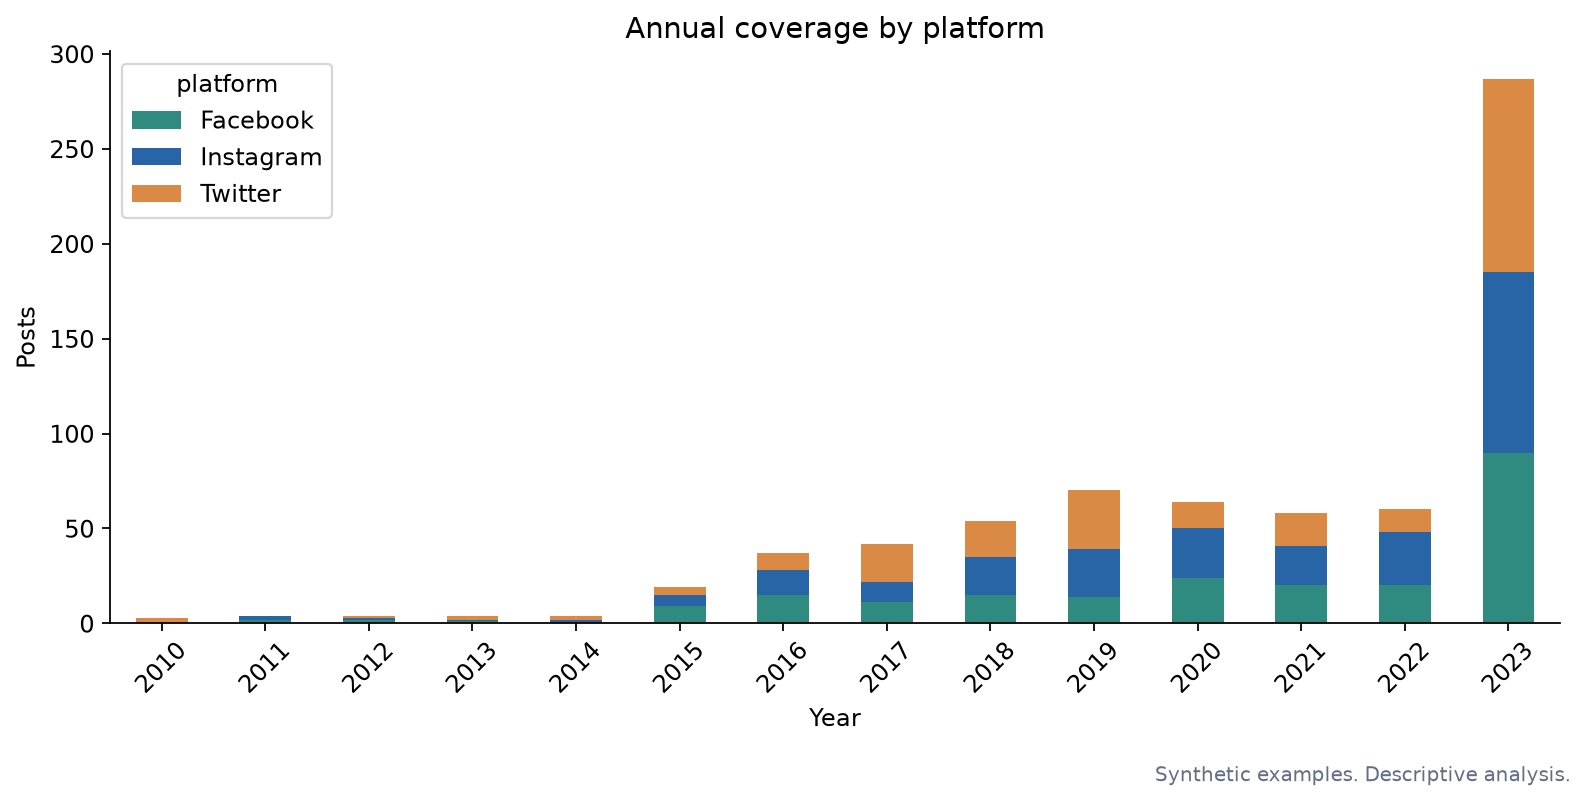

In [6]:
platform_summary = clean.groupby('platform').agg(posts=('source_record', 'size'), mean_interactions=('total_interactions', 'mean'),
                        median_interactions=('total_interactions', 'median')).reset_index()
platform_summary['share_pct'] = platform_summary.posts / len(clean) * 100
display(platform_summary)
display(pd.crosstab(clean.year, clean.platform))
print('Top five location labels share:', clean.country.value_counts().head(5).sum() / len(clean))
cross = pd.crosstab(clean.year, clean.platform)
cross.to_csv(BASE / 'tables/year_platform_coverage.csv')
normalized_year = pd.crosstab(clean.year, clean.sentiment, normalize='index').mul(100)
normalized_year.to_csv(BASE / 'tables/year_sentiment_pct.csv')
normalized_country = pd.crosstab(clean.country, clean.sentiment, normalize='index').mul(100)
normalized_country.to_csv(BASE / 'tables/country_sentiment_pct.csv')
fig, ax = plt.subplots(figsize=(10, 5))
cross.plot.bar(stacked=True, ax=ax, color=['#2f8b80', '#2865a7', '#db8a45'])
ax.set(title='Annual coverage by platform', ylabel='Posts', xlabel='Year')
ax.tick_params(axis='x', rotation=45)
save_chart(fig, '10_year_platform_coverage.png')

Constant numeric features: {'hashtag_count': 1}
Likes exactly twice retweets: 412 / 710
Repeated text rows: 8


,likes,retweets,total_interactions,text_word_count
likes,1.000000,0.998470,0.999830,0.209431
retweets,0.998470,1.000000,0.999321,0.210523
total_interactions,0.999830,0.999321,1.000000,0.209867
text_word_count,0.209431,0.210523,0.209867,1.000000


,feature,lower_fence,upper_fence,flagged_posts,action
0,likes,12.5,72.5,18,retained for inspection
1,retweets,7.5,35.5,25,retained for inspection
2,total_interactions,20.0,108.0,18,retained for inspection
3,text_word_count,-3.0,29.0,0,retained for inspection


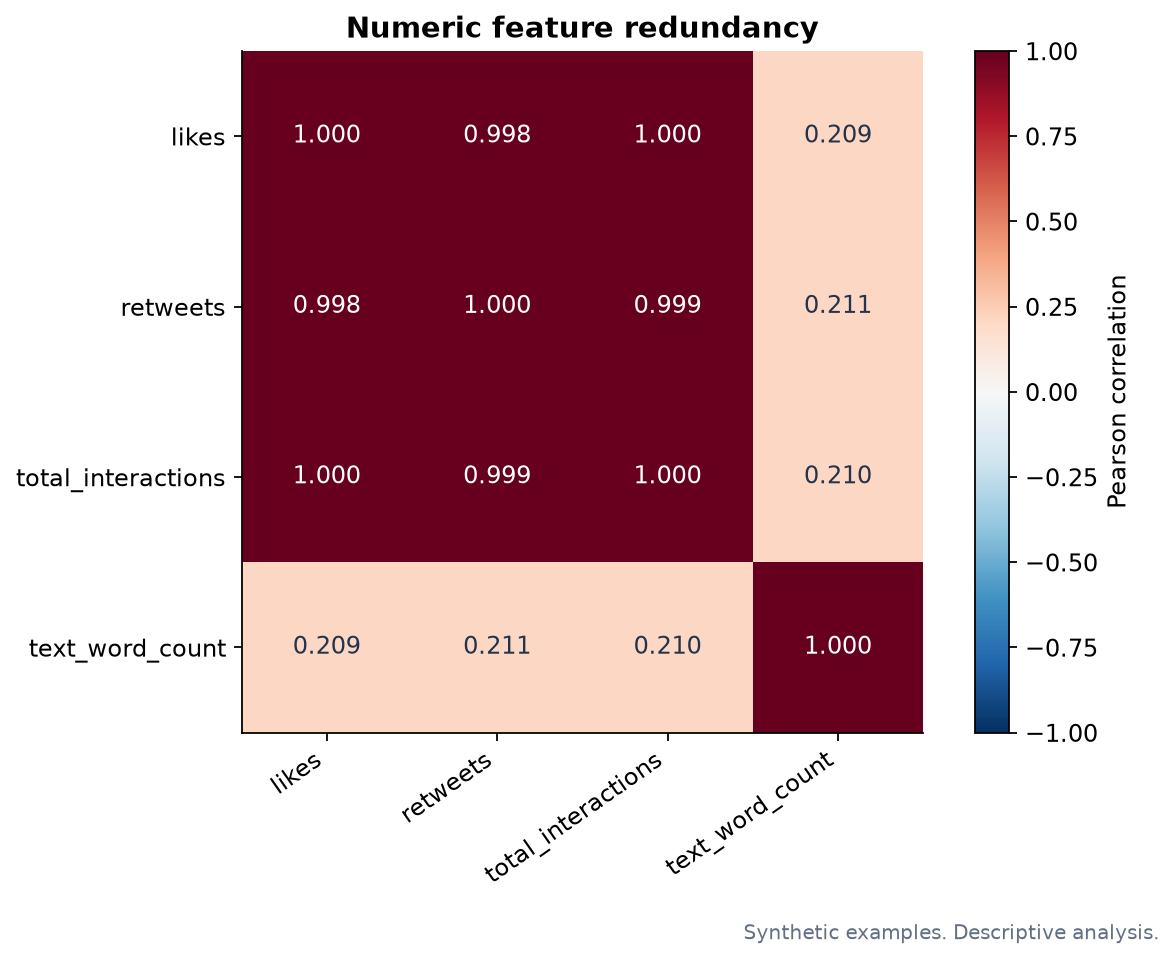

In [7]:
selected = clean[['likes', 'retweets', 'total_interactions', 'text_word_count']].astype(float)
pearson = selected.corr(method='pearson')
spearman = selected.rank().corr()
pearson.to_csv(BASE / 'tables/pearson_correlations.csv')
spearman.to_csv(BASE / 'tables/spearman_correlations.csv')
constant = clean.select_dtypes(include='number').nunique().loc[lambda s: s < 2]
print('Constant numeric features:', constant.to_dict())
print('Likes exactly twice retweets:', int(clean.likes.eq(2 * clean.retweets).sum()), '/', len(clean))
print('Repeated text rows:', int(clean.repeated_text.sum()))
display(pearson)
# Tukey IQR flags support inspection. They are not automatic deletion rules.
outlier_rows = []
for name in ['likes', 'retweets', 'total_interactions', 'text_word_count']:
    x = clean[name].to_numpy(dtype=float)
    q1, q3 = np.quantile(x, [.25, .75]); iqr = q3 - q1
    flag = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    outlier_rows.append({'feature': name, 'lower_fence': q1 - 1.5 * iqr, 'upper_fence': q3 + 1.5 * iqr,
                         'flagged_posts': int(flag.sum()), 'action': 'retained for inspection'})
outliers = pd.DataFrame(outlier_rows)
outliers.to_csv(BASE / 'tables/outlier_inspection.csv', index=False)
display(outliers)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pearson.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(pearson)), pearson.columns, rotation=35, ha='right')
ax.set_yticks(range(len(pearson)), pearson.index)
for i in range(len(pearson)):
    for j in range(len(pearson)):
        value = pearson.iloc[i, j]
        ax.text(j, i, f'{value:.3f}', ha='center', va='center', color='white' if abs(value) > .7 else '#243349')
ax.set_title('Numeric feature redundancy', fontweight='bold')
fig.colorbar(im, ax=ax, label='Pearson correlation')
save_chart(fig, '11_feature_correlations.png')

Exact normalized label/hashtag matches: 70.1%
This diagnostic checks exact normalized matches only. It does not detect synonyms or prove leakage.


,term,posts,post_share_pct
0,new,41,5.774648
1,each,39,5.492958
2,day,26,3.661972
3,feeling,26,3.661972
4,after,25,3.521127
5,night,23,3.239437
6,joy,23,3.239437
7,heart,23,3.239437
8,world,21,2.957746
9,beauty,20,2.816901


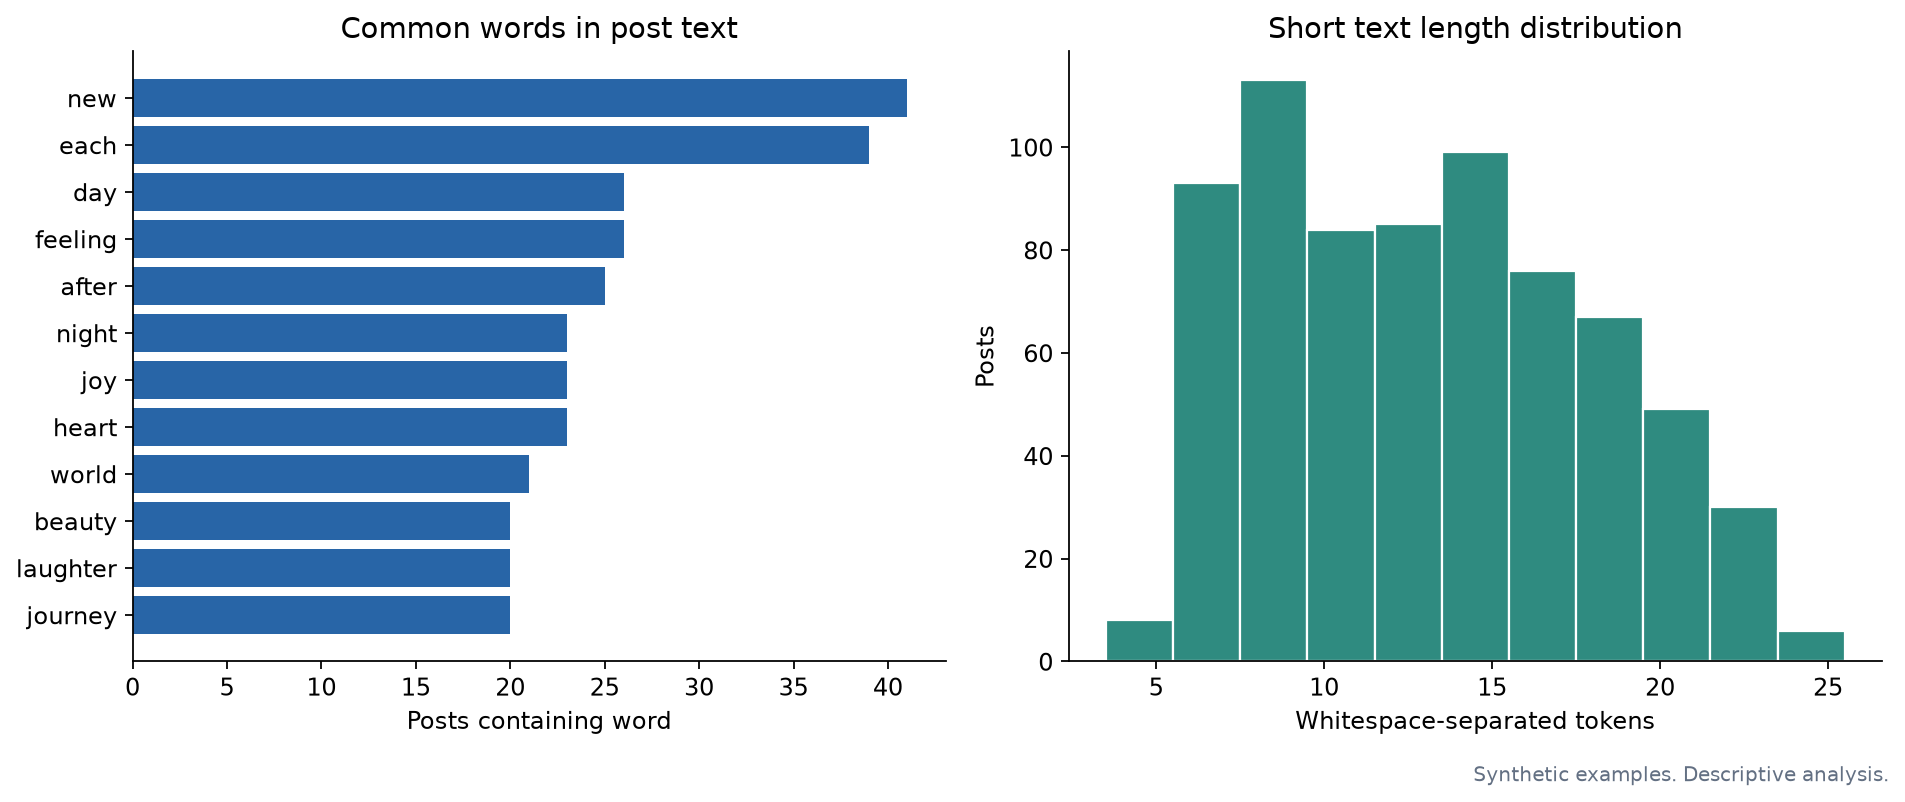

In [8]:
# Document frequency counts a word at most once per post. No vocabulary is fitted for modeling.
# Remove a short documented list of function words only for the descriptive chart.
display_stopwords = set('the a an and or to of in on at for with is are was were be been being i my me we our you your it its this that from as by into through while where when like but so'.split())
document_frequency = Counter()
for value in clean.text_lower:
    words = set(re.findall(r"[a-z]+(?:'[a-z]+)?", value))
    document_frequency.update(w for w in words if len(w) > 2 and w not in display_stopwords)
terms = pd.DataFrame(document_frequency.most_common(), columns=['term', 'posts'])
terms['post_share_pct'] = terms.posts / len(clean) * 100
terms.to_csv(BASE / 'tables/text_document_frequency.csv', index=False)
normalize_label = lambda value: re.sub(r'[^a-z0-9]', '', value.lower())
clean['hashtag_matches_supplied_label'] = clean.apply(
    lambda row: normalize_label(row.sentiment) in [normalize_label(t) for t in row.hashtag_list], axis=1)
cue_share = clean.hashtag_matches_supplied_label.mean()
pd.DataFrame({'measure': ['hashtag matches original label', 'other'],
              'posts': [int(clean.hashtag_matches_supplied_label.sum()), int((~clean.hashtag_matches_supplied_label).sum())]}).to_csv(BASE / 'tables/hashtag_label_cues.csv', index=False)
print(f'Exact normalized label/hashtag matches: {cue_share:.1%}')
print('This diagnostic checks exact normalized matches only. It does not detect synonyms or prove leakage.')
display(terms.head(15))
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
term_view = terms.head(12).iloc[::-1]
axs[0].barh(term_view.term, term_view.posts, color='#2865a7')
axs[0].set(title='Common words in post text', xlabel='Posts containing word')
axs[1].hist(clean.text_word_count, bins=np.arange(3.5, 26.5, 2), color='#2f8b80', edgecolor='white')
axs[1].set(title='Short text length distribution', xlabel='Whitespace-separated tokens', ylabel='Posts')
save_chart(fig, '12_text_exploration.png')

## Problem formulation and draft target
**Primary problem:** given the text of a previously unseen simulated post, classify
its sentiment polarity as Positive, Negative or Neutral using a reviewed annotation
rubric. Evaluate on held-out text groups using macro-F1 and per-class support.

Existing labels are the basis for a **draft mapping**, not independently validated
truth. A conservative lookup proposes polarity for clear labels and marks the rest
`Needs review`. The group must inspect the post text before accepting the target,
especially mixed, contextual, topic-like and low-support labels. No training results
are claimed. Unreviewed labels never default to Neutral.

Three polarity classes fit the stated sentiment task and avoid treating synonymous
emotion words as separate targets. Neutral may remain sparse, so taxonomy review
is a prerequisite to Week 5. Original emotion classification can remain a stretch goal.

In [9]:
positive = set('Accomplishment|Admiration|Adoration|Affection|Amusement|Appreciation|Blessed|Calmness|Celebration|Confidence|Confident|Contentment|Coziness|Ecstasy|Elation|Empowerment|Enchantment|Enjoyment|Enthusiasm|Euphoria|Excitement|FestiveJoy|Free-spirited|Friendship|Fulfillment|Grateful|Gratitude|Happiness|Happy|Harmony|Heartwarming|Hope|Hopeful|Inspiration|Inspired|Joy|Joy in Baking|JoyfulReunion|Kind|Kindness|Love|Optimism|Overjoyed|Playful|PlayfulJoy|Positive|Positivity|Pride|Proud|Rejuvenation|Relief|Romance|Satisfaction|Serenity|Success|Thrill|Tranquility|Triumph|Zest'.split('|'))
negative = set('Anger|Anxiety|Apprehensive|Bad|Betrayal|Bitter|Bitterness|Boredom|Desolation|Despair|Desperation|Devastated|Disappointed|Disappointment|Disgust|Embarrassed|Envious|Envy|Exhaustion|Fear|Fearful|Frustrated|Frustration|Grief|Hate|Heartache|Heartbreak|Helplessness|Intimidation|Isolation|Jealous|Jealousy|Loneliness|LostLove|Melancholy|Negative|Regret|Resentment|Sad|Sadness|Shame|Sorrow|Suffering'.split('|'))
assert not positive.intersection(negative)
def draft_polarity(label):
    if label in positive: return 'Positive'
    if label in negative: return 'Negative'
    if label == 'Neutral': return 'Neutral'
    return 'Needs review'
mapping = support[['sentiment', 'posts']].copy()
mapping['proposed_polarity'] = mapping.sentiment.map(draft_polarity)
mapping['rationale'] = np.where(mapping.proposed_polarity.eq('Needs review'),
    'Label alone is contextual, mixed, topic-like or ambiguous. Inspect every associated post.',
    'Provisional ordinary-language valence. Inspect post text for negation, sarcasm and label consistency.')
mapping['review_status'] = 'Unreviewed'
mapping['reviewer_1_decision'] = ''
mapping['reviewer_2_decision'] = ''
mapping['final_polarity'] = ''
mapping['adjudication_notes'] = ''
# Keep human edits in a separate review file. Reruns refresh the proposal only.
mapping.to_csv(BASE / 'data/polarity_mapping_proposed.csv', index=False)
clean['polarity_draft'] = clean.sentiment.map(draft_polarity)
draft_summary = clean.polarity_draft.value_counts().rename_axis('polarity_draft').reset_index(name='posts')
draft_summary['share_pct'] = draft_summary.posts / len(clean) * 100
draft_summary.to_csv(BASE / 'tables/polarity_draft_distribution.csv', index=False)
corpus = clean[['source_record', 'text_group_id', 'text', 'sentiment', 'polarity_draft']].copy()
corpus['target_review_status'] = 'Unreviewed'
corpus.to_csv(BASE / 'data/classification_corpus_draft.csv', index=False)
# A review worksheet samples up to 20 rows per draft category (at most 80 rows).
# It is a prioritization aid, not an evaluation or prevalence estimate.
review = clean.groupby('polarity_draft', group_keys=False).sample(frac=1, random_state=6074)
review = review.groupby('polarity_draft', group_keys=False).head(20)
review = review[['source_record', 'text', 'sentiment', 'polarity_draft']].copy()
review['reviewer_1_label'] = ''; review['reviewer_2_label'] = ''; review['final_label'] = ''; review['notes'] = ''
review.to_csv(BASE / 'data/annotation_review_sample_proposed.csv', index=False)
display(draft_summary)
print('Review worksheet rows:', len(review), '(up to 20 per draft group).')

,polarity_draft,posts,share_pct
0,Positive,328,46.197183
1,Needs review,201,28.309859
2,Negative,163,22.957746
3,Neutral,18,2.535211


Review worksheet rows: 78 (up to 20 per draft group).


## Feature selection
Primary input: the normalized `text` field only. Fit TF-IDF after splitting in Week 5.
Preserve punctuation, emoji and negation in stored text. Tokenization and preprocessing
are model choices to compare later, not irreversible cleaning choices.

Use `text_group_id` for group separation and `source_record` for traceability.
Exclude supplied labels and draft targets from predictors. Reserve platform, geography,
timestamps, hashtags, user IDs and engagement for descriptive analysis and later error
breakdowns. Engagement occurs after posting and would be unavailable for a text-only
prediction at publication. Hashtag counts are constant. Likes and retweets are redundant.

In [10]:
feature_rows = []
for c in clean.columns:
    if c == 'text':
        role, why = 'Primary text input', 'Text available at prediction time; fit vectorizer on training folds only.'
    elif c in ['sentiment', 'polarity_draft', 'hashtag_matches_supplied_label']:
        role, why = 'Target or target-derived. Exclude from predictors', 'Supplied/proposed outcomes or a diagnostic derived from the target.'
    elif c == 'text_group_id':
        role, why = 'Split grouping only', 'Keep identical normalized text together across training and evaluation.'
    elif c in ['source_record', 'source_index_1', 'source_index_2', 'user']:
        role, why = 'Identifier. Exclude from predictors', 'Traceability only; arbitrary identifiers can encourage memorization.'
    elif c == 'hashtag_count':
        role, why = 'EDA only. Drop from baseline', 'Constant at two for all retained posts.'
    elif c in ['likes', 'retweets', 'total_interactions', 'log1p_interactions']:
        role, why = 'EDA only. Exclude from text classifier', 'Post-publication outcomes; engagement fields are highly redundant.'
    elif c in ['hashtags', 'hashtag_list']:
        role, why = 'EDA only. Reserve for sensitivity analysis', 'Explicit sentiment cues may make synthetic labels easy to recover; compare after removing cues.'
    elif c in ['text_lower', 'text_char_count', 'text_word_count']:
        role, why = 'Candidate text transformation or auxiliary feature', 'Preserve as EDA features; baseline uses text only to avoid duplicate representations.'
    else:
        role, why = 'EDA or evaluation breakdown only', 'Context and quality flags do not enter the initial text-only baseline.'
    feature_rows.append({'feature': c, 'role': role, 'reason': why})
feature_selection = pd.DataFrame(feature_rows)
feature_selection.to_csv(BASE / 'tables/feature_selection.csv', index=False)
display(feature_selection)

,feature,role,reason
0,source_record,Identifier. Exclude from predictors,Traceability only; arbitrary identifiers can e...
1,source_index_1,Identifier. Exclude from predictors,Traceability only; arbitrary identifiers can e...
2,source_index_2,Identifier. Exclude from predictors,Traceability only; arbitrary identifiers can e...
3,text,Primary text input,Text available at prediction time; fit vectori...
4,sentiment,Target or target-derived. Exclude from predictors,Supplied/proposed outcomes or a diagnostic der...
5,timestamp,EDA or evaluation breakdown only,Context and quality flags do not enter the ini...
6,user,Identifier. Exclude from predictors,Traceability only; arbitrary identifiers can e...
7,platform,EDA or evaluation breakdown only,Context and quality flags do not enter the ini...
8,hashtags,EDA only. Reserve for sensitivity analysis,Explicit sentiment cues may make synthetic lab...
9,retweets,EDA only. Exclude from text classifier,Post-publication outcomes; engagement fields a...


## EDA conclusions and Week 5 handoff
- The raw file contains 732 rows. Removing 22 repeated records leaves 710 posts.
- All parsed dates and nonnegative integer engagement counts pass checks. No missing
  cells occur. Uneven dates and synthetic origin limit interpretation of trends.
- Sentiment labels reduce from 279 raw values to 191 after whitespace normalization.
  Eighty-one labels occur once. A model with all original labels is not the primary plan.
- Likes and retweets have Pearson correlation approximately 0.9985. Every retained post
  has two extracted hashtags. These features provide little independent variation.
- Four identical-text groups cover eight retained records. No identical text group has
  conflicting original labels. A group split is still required to prevent direct overlap.
- The draft polarity corpus remains unreviewed. Team members must adjudicate mixed or
  unclear examples and verify the proposed mappings against text before Week 5.

**Later evaluation plan, not executed here:** freeze a reviewed corpus, use an approximately
80/20 split grouped by text_group_id with class proportions inspected, and keep the test set
untouched. Compare a majority-class baseline, TF-IDF with logistic regression and TF-IDF
with a linear SVM using group-aware cross-validation in training. Select fold count based
on the smallest reviewed class. Report macro-F1, balanced accuracy, per-class precision /
recall / F1 / support and a confusion matrix. Do not fit vocabulary or resample before
splitting. A small neutral class and synthetic labels limit the scope of evaluation.

**Instructor feedback requested:** Is a three-class polarity target appropriate? Should the
project keep the synthetic corpus for demonstration, or add a real annotated corpus for
external evaluation? What should the team do with ambiguous examples and sparse Neutral?

In [11]:
assert len(clean) == 710 and len(raw) == 732
assert support.posts.sum() == len(clean)
assert mapping.sentiment.is_unique and len(mapping) == clean.sentiment.nunique()
assert clean.text_group_id.nunique() == 706
assert not clean.groupby('text_group_id').polarity_draft.nunique().gt(1).any()
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == input_hash
summary = {
    'raw_rows': len(raw), 'clean_rows': len(clean), 'removed_duplicates': len(removed),
    'label_count': len(support), 'singleton_labels': int(support.posts.eq(1).sum()),
    'hashtag_label_match_posts': int(clean.hashtag_matches_supplied_label.sum()),
    'hashtag_label_match_pct': float(cue_share * 100),
    'draft_polarity_counts': clean.polarity_draft.value_counts().to_dict(),
    'review_worksheet_rows': len(review), 'input_sha256': input_hash,
    'no_models_trained': True, 'no_hypothesis_tests_run': True,
}
(BASE / 'tables/weeks_1_3_metrics.json').write_text(json.dumps(summary, indent=2))
print('Reconciliation passed. Original CSV unchanged. Modeling and hypothesis testing remain future work.')
display(pd.Series(summary, name='result').to_frame())

Reconciliation passed. Original CSV unchanged. Modeling and hypothesis testing remain future work.


,result
raw_rows,732
clean_rows,710
removed_duplicates,22
label_count,191
singleton_labels,81
hashtag_label_match_posts,498
hashtag_label_match_pct,70.140845
draft_polarity_counts,"{'Positive': 328, 'Needs review': 201, 'Negati..."
review_worksheet_rows,78
input_sha256,725c6f7bc928c2bf741094f37078024b305982523fe6d0...
